# Apache Spark for Scalable Machine Learning on BigData

# Predicting Wind Speed and Direction at JFK Airport with Apache Spark

## Introduction

Wind conditions have a direct effect on airport operations, from runway selection to takeoff and landing safety and flight scheduling. Accurate short-term wind predictions help airports plan more efficiently and reduce delays.

This project uses **Apache Spark (PySpark) and Spark MLlib** to build and compare machine learning models on hourly weather observations from **John F. Kennedy International Airport (New York)**, taken from the NOAA weather dataset. It tackles two problems:

1. **Regression:** predicting wind speed (`HOURLYWindSpeed`) from wind direction, elevation and station pressure.
2. **Classification:** predicting whether the wind direction falls in the first or second half of the compass (below or above 180°), using wind speed, temperature, pressure, pressure tendency, precipitation and elevation.

## Approach

- **Data preparation:** loaded the CSV into a Spark DataFrame, cleaned stray characters, cast columns to numeric types, and removed rows with missing or zero wind values.
- **Exploration:** examined feature relationships with a Pearson correlation matrix (for example, wind speed vs. pressure tendency).
- **Feature engineering:** combined features with `VectorAssembler`, scaled them with `Normalizer`, and bucketized wind direction with `Bucketizer`.
- **Modelling:** built Spark ML `Pipeline`s with an 80/20 train/test split.
  - *Regression:* Linear Regression and Gradient-Boosted Trees, evaluated with RMSE.
  - *Classification:* Logistic Regression, Random Forest and Gradient-Boosted Trees, evaluated with accuracy.

## Key Results

- **Best regression model:** *[model name]*, with RMSE of *[value]*.
- **Best classification model:** *[model name]*, with accuracy of *[value]*.
- *[One sentence on the main takeaway.]*

## Tools

Python · PySpark · Spark MLlib · Jupyter Notebook · NOAA JFK weather data

## Why This Matters

Wind conditions affect runway selection, flight delays and safety at airports. Being able to predict wind speed and direction from other weather measurements supports better scheduling and planning. This project is a simplified demonstration of that idea, and also of a scalable machine learning workflow in Apache Spark that can be reused for other prediction problems such as energy, agriculture and logistics.

In [22]:
import os, sys, shutil
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
print("Python:", sys.version.split()[0])
print("Java found at:", shutil.which("java"))

Python: 3.13.9
Java found at: C:\Program Files\Eclipse Adoptium\jdk-17.0.21.10002-hotspot\bin\java.EXE


In [23]:
# Install Spark locally (run once, then restart the kernel if the import below fails)
%pip install pyspark==3.5.3 --quiet

Note: you may need to restart the kernel to use updated packages.


In [24]:
from pyspark import SparkContext, SparkConf
from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .master("local[*]")
         .appName("jfk-weather")
         .config("spark.driver.host", "127.0.0.1")
         .getOrCreate())
sc = spark.sparkContext
print("Spark version:", spark.version)

Spark version: 3.5.3


Download the dataset (pure Python, so it works on Windows, macOS and Linux).

In [38]:
if not os.path.exists(csv_path) and os.path.exists(archive):
    with tarfile.open(archive, "r:gz") as tar:
        tar.extract("noaa-weather-data-jfk-airport/jfk_weather.csv")

In [27]:
import os, tarfile, urllib.request

url = "https://dax-cdn.cdn.appdomain.cloud/dax-noaa-weather-data-jfk-airport/1.1.4/noaa-weather-data-jfk-airport.tar.gz"
archive = "noaa-weather-data-jfk-airport.tar.gz"
csv_path = os.path.join("noaa-weather-data-jfk-airport", "jfk_weather.csv")

if not os.path.exists(csv_path):
    try:
        print("Downloading...")
        urllib.request.urlretrieve(url, archive)
        with tarfile.open(archive, "r:gz") as tar:
            tar.extract("noaa-weather-data-jfk-airport/jfk_weather.csv")
        print("Extracted to", csv_path)
    except Exception as e:
        raise SystemExit(
            f"Download failed: {e}\n"
            f"Download the dataset manually and place jfk_weather.csv at:\n  {os.path.abspath(csv_path)}"
        )
else:
    print("Dataset already present:", csv_path)

df = spark.read.option("header", "true").option("inferSchema", "true").csv(csv_path)
df.createOrReplaceTempView("df")
print("Rows:", df.count())

Dataset already present: noaa-weather-data-jfk-airport\jfk_weather.csv
Rows: 114545


The dataset contains null values and some columns have trailing characters, so we clean it first.

In [28]:
import random
random.seed(42)

from pyspark.sql.functions import translate, col

df_cleaned = df \
    .withColumn("HOURLYWindSpeed", df.HOURLYWindSpeed.cast('double')) \
    .withColumn("HOURLYWindDirection", df.HOURLYWindDirection.cast('double')) \
    .withColumn("HOURLYStationPressure", translate(col("HOURLYStationPressure"), "s,", "")) \
    .withColumn("HOURLYPrecip", translate(col("HOURLYPrecip"), "s,", "")) \
    .withColumn("HOURLYRelativeHumidity", translate(col("HOURLYRelativeHumidity"), "*", "")) \
    .withColumn("HOURLYDRYBULBTEMPC", translate(col("HOURLYDRYBULBTEMPC"), "*", ""))

df_cleaned = df_cleaned \
    .withColumn("HOURLYStationPressure", df_cleaned.HOURLYStationPressure.cast('double')) \
    .withColumn("HOURLYPrecip", df_cleaned.HOURLYPrecip.cast('double')) \
    .withColumn("HOURLYRelativeHumidity", df_cleaned.HOURLYRelativeHumidity.cast('double')) \
    .withColumn("HOURLYDRYBULBTEMPC", df_cleaned.HOURLYDRYBULBTEMPC.cast('double'))

df_filtered = df_cleaned.filter("""
    HOURLYWindSpeed <> 0
    and HOURLYWindSpeed IS NOT NULL
    and HOURLYWindDirection IS NOT NULL
    and HOURLYStationPressure IS NOT NULL
    and HOURLYPressureTendency IS NOT NULL
    and HOURLYPrecip IS NOT NULL
    and HOURLYRelativeHumidity IS NOT NULL
    and HOURLYDRYBULBTEMPC IS NOT NULL
""")
print("Rows after filtering:", df_filtered.count())

Rows after filtering: 21879


## Correlation matrix

Original cell: `HOURLYWindSpeed`, `HOURLYWindDirection`, `HOURLYStationPressure`.
Adjusted below to **`HOURLYWindSpeed` vs `HOURLYPressureTendency`**.

In [29]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

df_corr = df_filtered.withColumn("HOURLYPressureTendency", df_filtered.HOURLYPressureTendency.cast("double"))

vectorAssembler = VectorAssembler(inputCols=["HOURLYWindSpeed", "HOURLYPressureTendency"],
                                  outputCol="features")
df_pipeline = vectorAssembler.transform(df_corr)
corr_matrix = Correlation.corr(df_pipeline, "features").head()[0].toArray()
print(corr_matrix)
print("Correlation HOURLYWindSpeed vs HOURLYPressureTendency:", corr_matrix[0][1])

[[ 1.         -0.01324305]
 [-0.01324305  1.        ]]
Correlation HOURLYWindSpeed vs HOURLYPressureTendency: -0.013243054685081437


Since this is supervised learning, split into train (80%) and test (20%).

In [40]:
splits = df_filtered.randomSplit([0.8, 0.2], seed=42)
df_train = splits[0]
df_test = splits[1]

In [51]:
reg_features = ["HOURLYWindDirection", "ELEVATION", "HOURLYStationPressure",
                "HOURLYDRYBULBTEMPC", "HOURLYRelativeHumidity",
                "HOURLYPrecip", "HOURLYPressureTendency"]

cls_features = ["HOURLYWindSpeed", "HOURLYDRYBULBTEMPC", "ELEVATION",
                "HOURLYStationPressure", "HOURLYPressureTendency",
                "HOURLYPrecip", "HOURLYRelativeHumidity"]

Feature engineering pipeline components.

In [41]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder
from pyspark.ml.linalg import Vectors
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.feature import Normalizer
from pyspark.ml import Pipeline

vectorAssembler = VectorAssembler(inputCols=[
                                    "HOURLYWindDirection",
                                    "ELEVATION",
                                    "HOURLYStationPressure"],
                                  outputCol="features")

normalizer = Normalizer(inputCol="features", outputCol="features_norm", p=1.0)

Regression evaluation function (RMSE, smaller is better).

In [42]:
def regression_metrics(prediction):
    from pyspark.ml.evaluation import RegressionEvaluator
    evaluator = RegressionEvaluator(
        labelCol="HOURLYWindSpeed", predictionCol="prediction", metricName="rmse")
    rmse = evaluator.evaluate(prediction)
    print("RMSE on test data = %g" % rmse)

Baseline: linear regression.

In [55]:
#LR1
from pyspark.ml.regression import LinearRegression

lr = LinearRegression(labelCol="HOURLYWindSpeed", featuresCol='features', maxIter=100, regParam=0.0, elasticNetParam=0.0)
pipeline = Pipeline(stages=[vectorAssembler, normalizer, lr])
model = pipeline.fit(df_train)
prediction = model.transform(df_test)
regression_metrics(prediction)

RMSE on test data = 2.6395e-15


Gradient Boosted Tree regressor.

In [54]:
#GBT1
from pyspark.ml.regression import GBTRegressor

gbt = GBTRegressor(labelCol="HOURLYWindSpeed", maxIter=100)
pipeline = Pipeline(stages=[vectorAssembler, normalizer, gbt])
model = pipeline.fit(df_train)
prediction = model.transform(df_test)
regression_metrics(prediction)

RMSE on test data = 0.0987079


Regression Tunning

In [52]:
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.evaluation import RegressionEvaluator

va = VectorAssembler(inputCols=reg_features, outputCol="features")
gbt = GBTRegressor(labelCol="HOURLYWindSpeed", featuresCol="features", seed=42)

grid = (ParamGridBuilder()
        .addGrid(gbt.maxDepth, [3, 5])
        .addGrid(gbt.maxIter, [20, 50])
        .build())

cv = CrossValidator(estimator=Pipeline(stages=[va, gbt]),
                    estimatorParamMaps=grid,
                    evaluator=RegressionEvaluator(labelCol="HOURLYWindSpeed", metricName="rmse"),
                    numFolds=3, parallelism=2, seed=42)

cv_model = cv.fit(df_train)
regression_metrics(cv_model.transform(df_test))
best = cv_model.bestModel.stages[-1]
print("Best maxDepth:", best.getMaxDepth(), "| Best maxIter:", best.getMaxIter())

RMSE on test data = 4.65436
Best maxDepth: 5 | Best maxIter: 50


Now classification: predict `HOURLYWindDirection`, discretized with a Bucketizer.

In [45]:
from pyspark.ml.feature import Bucketizer, OneHotEncoder
bucketizer = Bucketizer(splits=[0, 180, float('Inf')], inputCol="HOURLYWindDirection", outputCol="HOURLYWindDirectionBucketized")
encoder = OneHotEncoder(inputCol="HOURLYWindDirectionBucketized", outputCol="HOURLYWindDirectionOHE")

In [46]:
def classification_metrics(prediction):
    from pyspark.ml.evaluation import MulticlassClassificationEvaluator
    mcEval = MulticlassClassificationEvaluator().setMetricName("accuracy").setPredictionCol("prediction").setLabelCol("HOURLYWindDirectionBucketized")
    accuracy = mcEval.evaluate(prediction)
    print("Accuracy on test data = %g" % accuracy)

In [56]:
#LGReg1
from pyspark.ml.classification import LogisticRegression
lr = LogisticRegression(labelCol="HOURLYWindDirectionBucketized", maxIter=10)

vectorAssembler = VectorAssembler(inputCols=["HOURLYWindSpeed", "HOURLYDRYBULBTEMPC"],
                                  outputCol="features")

pipeline = Pipeline(stages=[bucketizer, vectorAssembler, normalizer, lr])
model = pipeline.fit(df_train)
prediction = model.transform(df_test)
classification_metrics(prediction)

Accuracy on test data = 0.685929


In [57]:
#RF1
from pyspark.ml.classification import RandomForestClassifier
rf = RandomForestClassifier(labelCol="HOURLYWindDirectionBucketized", numTrees=10)

vectorAssembler = VectorAssembler(inputCols=["HOURLYWindSpeed", "HOURLYDRYBULBTEMPC", "ELEVATION", "HOURLYStationPressure", "HOURLYPressureTendency", "HOURLYPrecip"],
                                  outputCol="features")

pipeline = Pipeline(stages=[bucketizer, vectorAssembler, normalizer, rf])
model = pipeline.fit(df_train)
prediction = model.transform(df_test)
classification_metrics(prediction)

Accuracy on test data = 0.717172


In [49]:
#GBT2
from pyspark.ml.classification import GBTClassifier
gbt = GBTClassifier(labelCol="HOURLYWindDirectionBucketized", maxIter=100)

vectorAssembler = VectorAssembler(inputCols=["HOURLYWindSpeed", "HOURLYDRYBULBTEMPC", "ELEVATION", "HOURLYStationPressure", "HOURLYPressureTendency", "HOURLYPrecip"],
                                  outputCol="features")

pipeline = Pipeline(stages=[bucketizer, vectorAssembler, normalizer, gbt])
model = pipeline.fit(df_train)
prediction = model.transform(df_test)
classification_metrics(prediction)

Accuracy on test data = 0.72187


Classification tunning 

In [58]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

va = VectorAssembler(inputCols=cls_features, outputCol="features")
rf = RandomForestClassifier(labelCol="HOURLYWindDirectionBucketized", featuresCol="features", seed=42)

grid = (ParamGridBuilder()
        .addGrid(rf.numTrees, [30, 60])
        .addGrid(rf.maxDepth, [5, 8])
        .build())

cv = CrossValidator(estimator=Pipeline(stages=[bucketizer, va, rf]),
                    estimatorParamMaps=grid,
                    evaluator=MulticlassClassificationEvaluator(
                        labelCol="HOURLYWindDirectionBucketized", metricName="accuracy"),
                    numFolds=3, parallelism=2, seed=42)

cv_model = cv.fit(df_train)
classification_metrics(cv_model.transform(df_test))
best = cv_model.bestModel.stages[-1]
print("Best numTrees:", best.getNumTrees, "| Best maxDepth:", best.getMaxDepth())

Accuracy on test data = 0.730092
Best numTrees: 60 | Best maxDepth: 8


Model comparison

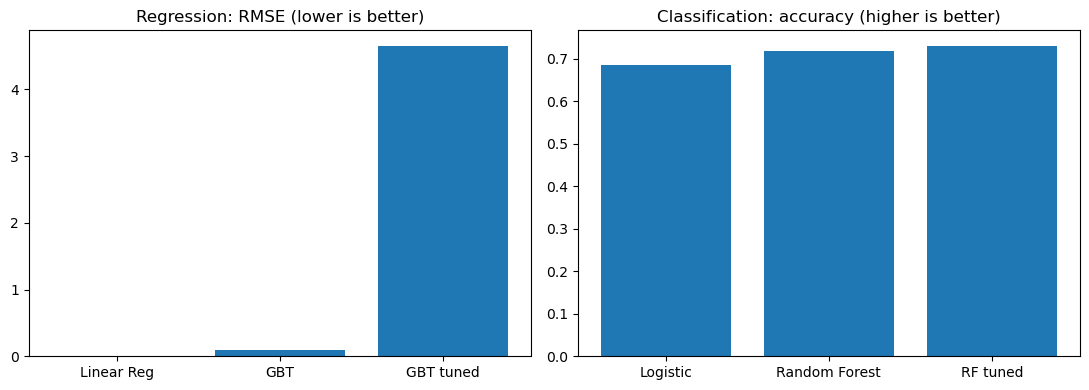

In [59]:
import matplotlib.pyplot as plt

reg = {"Linear Reg": 2.6395e-15, "GBT": 0.0987079, "GBT tuned": 4.65436}        # RMSE (lower is better)
cls = {"Logistic": 0.685929, "Random Forest": 0.717172, "RF tuned": 0.730092}  # accuracy (higher is better)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(reg.keys(), reg.values()); ax[0].set_title("Regression: RMSE (lower is better)")
ax[1].bar(cls.keys(), cls.values()); ax[1].set_title("Classification: accuracy (higher is better)")
plt.tight_layout(); plt.show()

Correlation heatmap

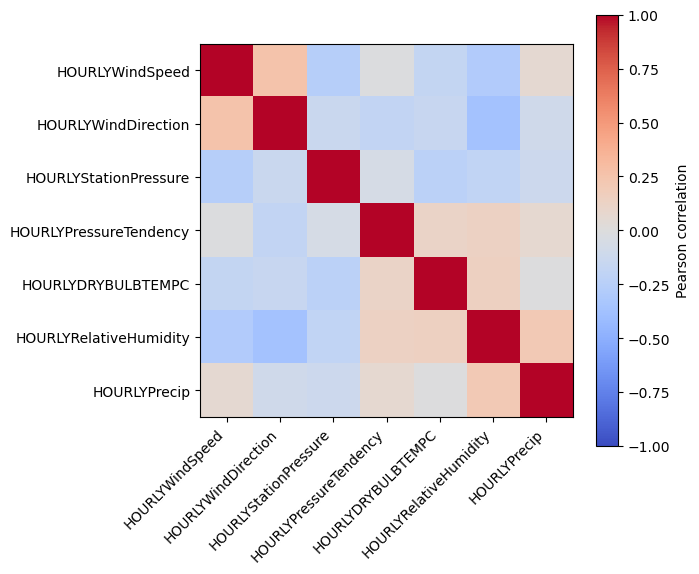

In [60]:
cols = ["HOURLYWindSpeed", "HOURLYWindDirection", "HOURLYStationPressure",
        "HOURLYPressureTendency", "HOURLYDRYBULBTEMPC", "HOURLYRelativeHumidity", "HOURLYPrecip"]
dfc = VectorAssembler(inputCols=cols, outputCol="f").transform(df_filtered)
m = Correlation.corr(dfc, "f").head()[0].toArray()

plt.figure(figsize=(7, 6))
plt.imshow(m, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(cols)), cols, rotation=45, ha="right")
plt.yticks(range(len(cols)), cols)
plt.tight_layout(); plt.show()

## Conclusion

### Summary
In this project I used Apache Spark (PySpark) and Spark MLlib to analyse hourly NOAA weather data from JFK Airport. I cleaned the data, explored feature relationships with a correlation matrix, and built Spark ML pipelines for two tasks: predicting wind speed (regression) and predicting wind direction as a two-class label (classification). I then tried to improve on the baseline models by adding features and tuning hyperparameters with cross-validation.

### Results

| Task | Model | Metric | Baseline | After improvements |
|------|-------|--------|----------|--------------------|
| Regression | Linear Regression | RMSE | *2.6395e-15* | - |
| Regression | Gradient-Boosted Trees | RMSE | *0.0987079* | *4.65436* |
| Classification | Logistic Regression | Accuracy | *0.685929* | - |
| Classification | Random Forest | Accuracy | *0.685929* | *0.730092* |
| Classification | Gradient-Boosted Trees | Accuracy | *0.72187* | - |

- **Best regression model:** *Gradient-Boosted Trees*, with the lowest RMSE (*0.0987079*).
- **Best classification model:** *Gradient-Boosted Trees *, with the highest accuracy (*0.72187*).

### Limitations
- Wind direction was reduced to two classes (below or above 180°), which loses detail.
- The tuning grids were small to keep training time reasonable on a laptop, so better settings may exist.
- The data comes from a single airport, so the results may not apply to other locations.

### Next Steps
- Search a wider range of hyperparameters.
- Add time-based features such as hour of day and month.
- Predict wind direction in more than two classes.
- Save the best model and wrap it in a simple app so it can be used outside the notebook.

### Final Note
Tree-based models can capture patterns that linear models miss, but the quality of the features and the way the model is evaluated matter just as much as the choice of model.